In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
from mytools.plot import (
    plot_heatmap,
    plot_heatmaps,
    plot_stack_fit_res,
    plot_axlines,
    plot_profile_2c,
    plot_sector,
    compare_profiles,
    save_plot,
    plot_hist
)
from mytools.utils import get_mask_sector
from mytools.estimate import get_signal_level
from mytools.data import read_h5, vitems

In [3]:
data_path = "../data/halo_subtracted_result_pca_halofitting_nfw_gaussian_const_sectormask_maskpeak_pixweight.h5"
vitems(data_path)

Item: crafts_df122k_rmfg0_xsize3000_nfs10
Type: Group
Attributes (0):
 None
Item: crafts_df122k_rmfg0_xsize3000_nfs10/fit_cov
Type: Dataset
Shape: (7, 7)
Dtype: float64
Attributes (0):
 None
Item: crafts_df122k_rmfg0_xsize3000_nfs10/fit_mask
Type: Dataset
Shape: (120, 120)
Dtype: bool
Attributes (0):
 None
Item: crafts_df122k_rmfg0_xsize3000_nfs10/fit_weights
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: crafts_df122k_rmfg0_xsize3000_nfs10/fitted
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: crafts_df122k_rmfg0_xsize3000_nfs10/res
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: crafts_df122k_rmfg0_xsize3000_nfs10/stack
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: crafts_df122k_rmfg10_xsize3000_nfs10
Type: Group
Attributes (0):
 None
Item: crafts_df122k_rmfg10_xsize3000_nfs10/fit_cov
Type: Dataset
Shape: (7, 7)
Dtype: float64
Attributes (0):
 None
Item: crafts_df122k_rmfg10

<Axes: title={'center': 'Halo peak mask'}, xlabel='X', ylabel='Y'>

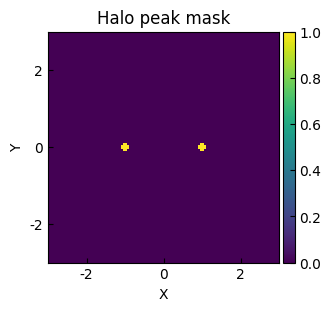

In [4]:
peakmask = get_mask_sector([0.,0.1], [-np.pi/2, np.pi/2])
plot_heatmap(peakmask, cbar_label='', title='Halo peak mask')

In [13]:
mode = 30
keys = [
    f"crafts_df122k_rmfg{mode}_xsize3000_nfs10/{k}"
    for k in ["stack", "fitted", "res", "fit_mask", "fit_cov", "fit_weights"]
]

stack, fitted, res, fit_mask, fit_cov, fit_weights = read_h5(data_path, keys)

In [14]:
def get_masked(d, mask):
    return np.ma.array(d, mask=mask)

stack = get_masked(stack, peakmask)
fitted = get_masked(fitted, peakmask)
res = get_masked(res, peakmask)

res_mean, res_std = res[fit_mask].mean(), res[fit_mask].std()
print(res_mean, res_std)

0.014646420661887791 8.03880111827597


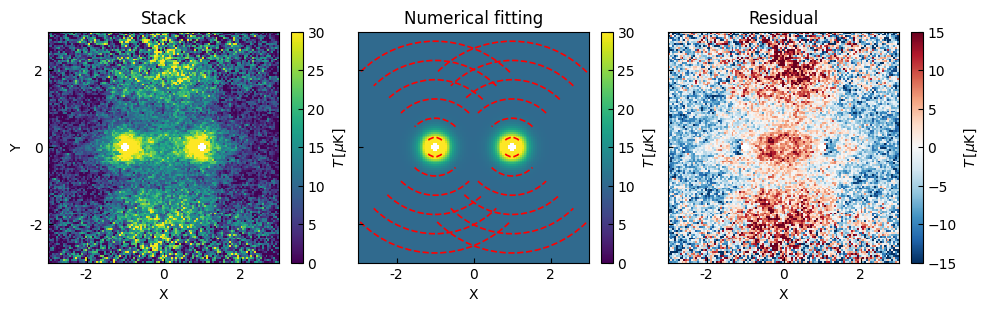

In [15]:
axes = plot_stack_fit_res(
    [stack, fitted, res],
    title=["Stack", "Numerical fitting", "Residual"],
    # vmax=[70, 70, 25],
    # vmin=[0, 0, -25]
    vmax=[30, 30, 15],
    vmin=[0, 0, -15]
)
plot_sector(axes[1], ec='r')
# plot_axlines(axes, vl=[40, 80], hl=[60], color='cyan')

fname = f'img_crafts_df122k_rmfg{mode}_xsize3000_nfs10_mean_halo_fitting_nfw_gaussian_const_sectormask_maskpeak_pixweight_stack_fit_res.png'
# save_plot(axes, fname)

<Axes: title={'center': 'Heatmap'}, xlabel='X', ylabel='Y'>

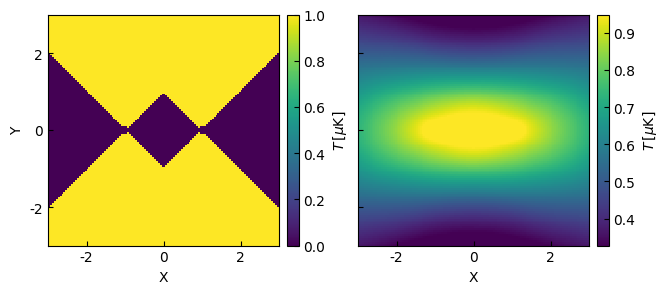

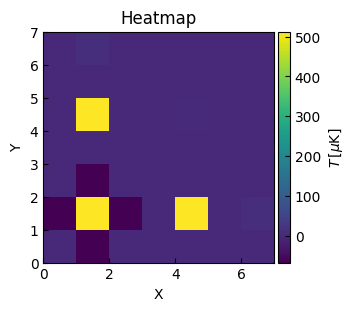

In [16]:
plot_heatmaps([fit_mask, fit_weights])
plot_heatmap(fit_cov, change_ticks=False)

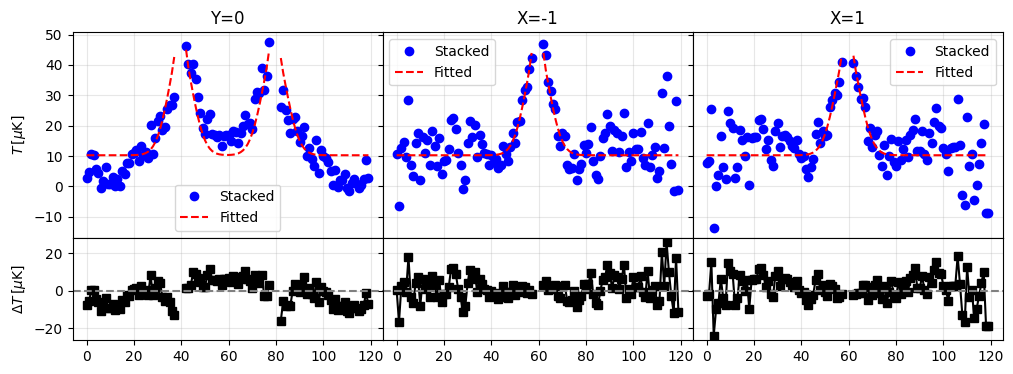

In [17]:
axes = compare_profiles([stack, fitted])
fname = f'img_crafts_df122k_rmfg{mode}_xsize3000_nfs10_mean_halo_fitting_nfw_gaussian_const_sectormask_maskpeak_pixweight_profiles_compare.png'
# save_plot(axes, fname)

Parameter names:
('amplitude_0', 'mean_0', 'stddev_0', 'amplitude_1')
Gauss fit parameters: [np.float64(7.068024110898947), np.float64(0.0), np.float64(0.34603288780943736), np.float64(1.1679138226414687)]
Gauss fit covariance (without fix mean): 
[[ 0.2301776   0.00520596 -0.1426988 ]
 [ 0.00520596  0.00119896 -0.01237723]
 [-0.1426988  -0.01237723  0.19089662]]
0 points clipped during sigma clipping.

Goodness of fit:
Chi-squared: 2550.481
Reduced chi-squared: 21.799
RMS residual: 4.610

width: 0.34603288780943736
width_pix: 7


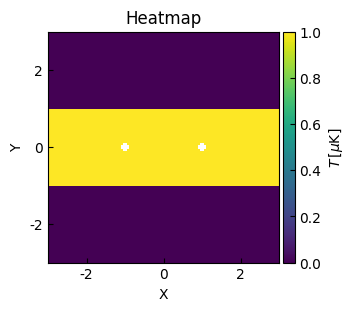

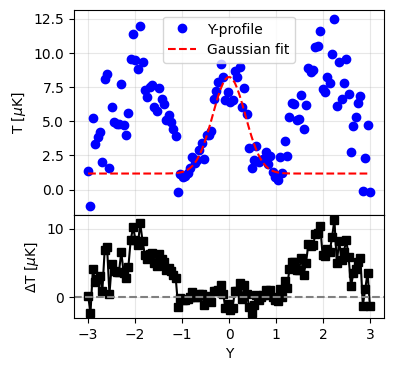

In [18]:
bounds = {
    "amplitude_0": (-np.inf, np.inf),  # amp > 0
    "stddev_0": (0., 0.6),  # sigma
}

weight = None
weight = np.ones_like(res)
weight[:40] = 0
weight[80:] = 0
plot_heatmap(weight)

lx, ly, clrb, params, cov = get_signal_level(
    res, weight, bounds=bounds, show_fit=True
)

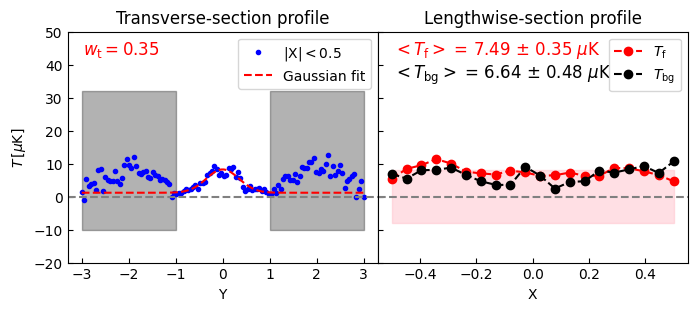

In [19]:
axes = plot_profile_2c(lx, ly, width=params[2])
axes[0].set_ylim(-20, 50)
axes[0].fill_betweenx([-10, 32], -3, -1, color="k", alpha=0.3)
axes[0].fill_betweenx([-10, 32], 1, 3, color="k", alpha=0.3)
# axes[0].set_ylim(-10, 25)
# axes[0].fill_betweenx([-5, 15], -3, -1, color="k", alpha=0.3)
# axes[0].fill_betweenx([-5, 15], 1, 3, color="k", alpha=0.3)
axes[1].fill_between(lx[-1], res_mean+res_std, res_mean - res_std, color='pink', alpha=0.5)

fname = f'img_crafts_df122k_rmfg{mode}_xsize3000_nfs10_mean_halo_fitting_nfw_gaussian_const_sectormask_maskpeak_pixweight_res_mask_signal.png'
# save_plot(axes, fname)

<Axes: title={'center': 'Signal level'}, ylabel='PDF'>

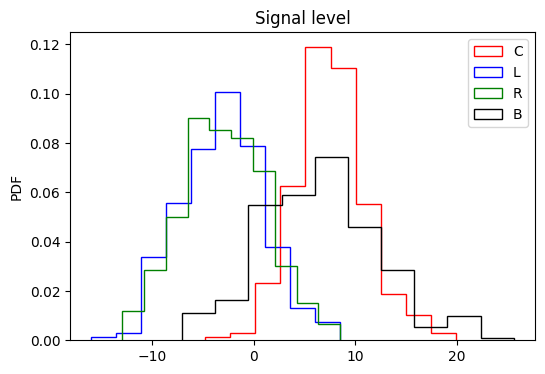

In [20]:

plot_hist(
    clrb, label=["C", "L", "R", "B"], color=["r", "b", "g", "k"], title="Signal level"
)